# Study area figures

Overview maps of the East River basin: (1) where the basin sits in Colorado relative to the four NISAR tracks, and (2) a DEM of the basin with the SNOTEL and wind stations.

Every stylistic choice (colors, line widths, label fonts, basemap, hillshade strength, ...) lives in the **Style settings** cells, so you can change the look of a figure without touching the plotting code. All maps are in the UTM zone of the NISAR data (EPSG:32613, UTM 13N) with an equal aspect ratio.

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import rioxarray  # noqa: F401
import geopandas as gpd
import shapely
import contextily as ctx
import py3dep
import asf_search as asf
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import LightSource, Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter
from rasterio import features
from shapely.geometry import box, shape
from seaborn import set_theme
set_theme()

import sys
import os
from pathlib import Path

# import from this repo 
project_root = str(Path(os.getcwd()).parent)
if project_root not in sys.path:
    sys.path.append(project_root)

%load_ext autoreload
%autoreload 2

First, we setup logging to get useful information and error messages. 

In [2]:
import logging

logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True 
)
logging.getLogger('asf_search').setLevel(logging.WARNING)   # asf_search logs every query at INFO

# Style settings

Everything you are likely to want to tweak is in this section. Colors can be any matplotlib color (name, hex, RGB tuple). Sizes of text and markers are in points, distances on the map are in meters.

## General

In [3]:
data_dir = "../data/"
out_dir = "../outputs/"

SAVE_FIGS = False      # if True, figures are written to out_dir as PNGs
FIG_DPI = 300          # resolution of the saved figures

# the UTM zone is taken from the ASO raster below (EPSG:32613, same as the NISAR cubes)
aso_file = data_dir + "aso/er_20260318/ASO_EastRiver_2026Mar18_swe_50m.tif"

## Basin outline

The basin outline is the footprint of the valid pixels of either the ASO SWE raster (`'aso'`) or the NISAR 80 m cube (`'nisar'`). The raw pixel mask is cleaned up a little (gaps closed, small specks dropped, edges simplified) so it draws as a smooth line.

In [4]:
BASIN_SOURCE = 'aso'        # 'aso' or 'nisar'
nisar_track, nisar_frame = 19, 21   # only used if BASIN_SOURCE == 'nisar'

BASIN_CLOSE_M = 200         # close gaps / holes narrower than ~2x this distance (m)
BASIN_MIN_AREA_KM2 = 1      # drop disconnected pieces smaller than this (km^2)
BASIN_SIMPLIFY_M = 40       # simplify tolerance for the outline (m)

## Figure 1: Colorado and NISAR tracks

`BASEMAPS` holds the basemaps you can pick from. To switch between satellite and street imagery, pass a different entry to `plot_colorado(...)` (done below) or change `BASEMAP_DEFAULT`. Any other contextily provider works too, e.g. `ctx.providers.CartoDB.Voyager` or `ctx.providers.OpenTopoMap`; run `ctx.providers` to see them all.

In [5]:
BASEMAPS = {
    'satellite': ctx.providers.Esri.WorldImagery,
    'street': ctx.providers.Esri.WorldStreetMap,   # or ctx.providers.OpenStreetMap.Mapnik
}
BASEMAP_DEFAULT = 'satellite'
BASEMAP_ZOOM = 'auto'           # 'auto' or an integer tile zoom level (higher = sharper but slower)
BASEMAP_ATTRIBUTION_SIZE = 6    # font size of the tile attribution text
BASEMAP_TILE_MARGIN_M = 100_000 # tiles are fetched this far beyond the map so warping to UTM leaves no blank corners (m)

CO_FIGSIZE = (8, 7)
CO_PAD_M = 25_000               # margin around Colorado + track footprints (m)

# Colorado state line: bounded by parallels 37 and 41 N and meridians 102.05 and 109.05 W
CO_BOUNDS_LONLAT = (-109.05, 37.0, -102.05, 41.0)
CO_STYLE = dict(facecolor='none', edgecolor='white', linewidth=1.5, linestyle='--',
                path_effects=[pe.withStroke(linewidth=3.5, foreground='black', alpha=0.6)])   # dark halo keeps it visible on any basemap

# NISAR footprints: one color per track. Fill is drawn with alpha so overlaps stay visible.
TRACK_COLORS = {19: '#ffd92f', 120: '#66c2a5', 128: '#fc8d62', 27: '#8da0cb'}
TRACK_FILL_ALPHA = 0.25
TRACK_EDGE_WIDTH = 1.8
TRACK_LEGEND_TITLE = 'NISAR tracks'
TRACK_LEGEND_LOC = 'upper left'
TRACK_LEGEND_LABEL = 'Track {track} (frame {frame})'   # filled in from the track/frame list

# East River basin on the Colorado map
BASIN_CO_STYLE = dict(facecolor='red', edgecolor='white', linewidth=1.2)
BASIN_CO_LABEL = dict(text='East River\nbasin', xytext=(-70, 45),     # label offset from basin (points)
                      fontsize=11, fontweight='bold', color='white', halo_color='black', halo_width=2.5)
BASIN_CO_ARROW = dict(arrowstyle='-', color='white', linewidth=1.5)

SCALEBAR_KM = 100               # length of the scale bar (km); None to hide it

## Figure 2: DEM, hillshade and stations

Station coordinates are in the table below (SNOTEL from the NRCS AWDB station metadata, wind stations from the MesoWest CSV headers). Each station has its own label offset (`dx`, `dy` in points from the marker) and alignment so close-together stations don't overlap. 

In [6]:
DEM_RES = 10                    # DEM resolution requested from 3DEP (m)
DEM_BUFFER_M = 2000             # buffer around the basin bounding box (m)
DEM_DOWNLOAD_PAD_M = 500        # extra DEM downloaded beyond the buffer so no edge pixels are missing (m)
DEM_CMAP = 'terrain'           # any matplotlib colormap, e.g. 'gist_earth', 'cividis', 'Greys_r'
DEM_VMIN, DEM_VMAX = None, None # elevation color limits (m); None = data min/max

HILLSHADE_AZIMUTH = 315         # direction of the light (degrees clockwise from north)
HILLSHADE_ALTITUDE = 45         # sun angle above the horizon (degrees)
HILLSHADE_VERT_EXAG = 1.0       # vertical exaggeration; raise to emphasize relief
HILLSHADE_STRENGTH = 0.5        # 0 = no hillshade, 1 = full; ~0.3-0.6 reads as "light"
HILLSHADE_BLEND = 'soft'        # matplotlib blend mode: 'soft', 'overlay' or 'hsv'

DEM_FIGSIZE = (8, 8)
DEM_TITLE = 'East River basin'
DEM_AXIS_KM = True              # label axes in km instead of m
DEM_SCALEBAR_KM = 5             # length of the scale bar (km); None to hide it

# basin outline: a white halo under a dark line stays visible on any terrain color
BASIN_DEM_STYLE = dict(edgecolor='black', linewidth=1.8, facecolor='none')
BASIN_DEM_HALO = dict(linewidth=3.8, edgecolor='white', alpha=0.8)    # set to None for no halo

# marker appearance per station type
MARKER_STYLE = {
    'snotel': dict(marker='^', s=110, facecolor='#e41a1c', edgecolor='white', linewidth=1.2, label='SNOTEL station'),
    'wind':   dict(marker='s', s=90,  facecolor='#377eb8', edgecolor='white', linewidth=1.2, label='Wind station'),
}

# station label appearance (applies to every label)
LABEL_STYLE = dict(fontsize=10, fontweight='bold', color='black', halo_color='white', halo_width=2.5)
LEGEND_STYLE = dict(loc='lower left', fontsize=9, framealpha=0.9)

STATIONS = [
    # name shown on the map, type, location (WGS84), label offset (points) and alignment
    dict(name='Butte',              kind='snotel', lat=38.89435, lon=-106.95327, dx=10,  dy=-6, ha='left',  va='top'),
    dict(name='Upper Taylor',       kind='snotel', lat=38.99071, lon=-106.74504, dx=-10, dy=-8, ha='right', va='top'),
    dict(name='Castle Peak',        kind='snotel', lat=39.00074, lon=-106.83912, dx=0,   dy=-10, ha='center', va='top'),
    dict(name='Schofield Pass',     kind='snotel', lat=39.01467, lon=-107.04933, dx=10,  dy=8,  ha='left',  va='bottom'),
    dict(name='Cinnamon Mtn',       kind='wind',   lat=38.99469, lon=-107.07081, dx=10,  dy=-8, ha='left',  va='top'),
    dict(name='Irwin Guides Ridge', kind='wind',   lat=38.90260, lon=-107.09769, dx=10,  dy=-8, ha='left',  va='top'),
]

# Load data and build the basin outline

The track/frame combinations are read from `scripts/slurm/tracks_frames.txt` so this notebook always matches the data downloads.

In [7]:
aso = rioxarray.open_rasterio(aso_file, masked=True).squeeze(drop=True)
crs = aso.rio.crs
crs

CRS.from_wkt('PROJCS["WGS 84 / UTM zone 13N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-105],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32613"]]')

Warning 1: DeprecationWarning: 'Memory' driver is deprecated since GDAL 3.11. Use 'MEM' onwards. Further messages of this type will be suppressed.
2026-10-14 21:46:58,853 - INFO - Basin area: 752 km^2


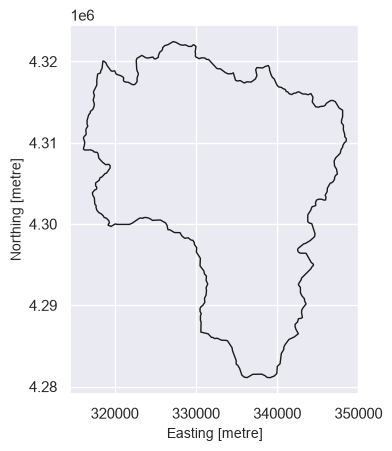

In [8]:
def basin_polygon(valid, close_m, min_area_km2, simplify_m):
    """Outline of a boolean ``valid`` raster (rioxarray) as a single cleaned-up shapely geometry."""
    mask = valid.values.astype('uint8')
    polys = [shape(g) for g, v in features.shapes(mask, mask=mask.astype(bool), transform=valid.rio.transform())]
    geom = shapely.unary_union(polys)
    geom = geom.buffer(close_m).buffer(-close_m)                       # close gaps
    parts = [p for p in shapely.get_parts(geom) if p.area > min_area_km2 * 1e6]
    parts = [shapely.Polygon(p.exterior) for p in parts]                # fill interior holes
    return shapely.unary_union(parts).simplify(simplify_m)


if BASIN_SOURCE == 'aso':
    valid = aso.notnull()
elif BASIN_SOURCE == 'nisar':
    nisar_80m = xr.open_zarr(data_dir + f'nisar/zarrs/track{str(nisar_track).zfill(3)}_frame{str(nisar_frame).zfill(3)}/snow_80m.zarr')
    valid = nisar_80m['elevation'].notnull().rio.write_crs(nisar_80m.rio.crs)
else:
    raise ValueError(f"BASIN_SOURCE must be 'aso' or 'nisar', got {BASIN_SOURCE!r}")

basin = gpd.GeoDataFrame(geometry=[basin_polygon(valid, BASIN_CLOSE_M, BASIN_MIN_AREA_KM2, BASIN_SIMPLIFY_M)], crs=valid.rio.crs).to_crs(crs)
logging.info(f"Basin area: {basin.area.iloc[0] / 1e6:.0f} km^2")
basin.plot(edgecolor='k', facecolor='none')
plt.gca().set_aspect('equal')

Get the footprint of each NISAR track/frame from ASF. The footprints are cached so the search only runs once. 

In [9]:
tracks_frames = pd.read_csv(
    Path(project_root) / 'scripts/slurm/tracks_frames.txt',
    sep=r'\s+', comment='#', header=None, usecols=[0, 1], names=['track', 'frame'],
)

footprint_file = Path(data_dir + 'nisar/track_footprints.gpkg')

def get_footprints(tracks_frames, cache):
    """Footprint polygon (EPSG:4326) of each track/frame, searched from ASF and cached to ``cache``."""
    if cache.exists():
        return gpd.read_file(cache)
    rows = []
    for track, frame in tracks_frames.itertuples(index=False):
        res = asf.search(dataset='NISAR', processingLevel='GUNW', relativeOrbit=int(track), frame=int(frame),
                         start='2025-12-01', end='2026-04-30', maxResults=1)
        rows.append(dict(track=int(track), frame=int(frame), geometry=shape(res[0].geometry)))
    footprints = gpd.GeoDataFrame(rows, crs='EPSG:4326')
    cache.parent.mkdir(parents=True, exist_ok=True)
    footprints.to_file(cache, driver='GPKG')
    return footprints

footprints = get_footprints(tracks_frames, footprint_file).to_crs(crs)
footprints

,track,frame,geometry
0,19,21,"POLYGON ((589926.972 4192842.751, 517409.351 4..."
1,120,21,"POLYGON ((404033.798 4195991.692, 336250.965 4..."
2,128,69,"POLYGON ((170669.299 4434769.356, 91305.866 42..."
3,27,69,"POLYGON ((351017.428 4433820.938, 276243.803 4..."


# Figure 1: Colorado with the NISAR tracks

In [10]:
def scalebar(ax, length_km, loc=(0.04, 0.04), color='white', halo='black', fontsize=9):
    """Draw a scale bar of ``length_km`` at axes-fraction ``loc`` (lower left of the bar)."""
    x0, x1 = ax.get_xlim(); y0, y1 = ax.get_ylim()
    xs = x0 + loc[0] * (x1 - x0)
    ys = y0 + loc[1] * (y1 - y0)
    halo_fx = [pe.withStroke(linewidth=3.5, foreground=halo)]
    ax.plot([xs, xs + length_km * 1000], [ys, ys], color=color, linewidth=3, solid_capstyle='butt', path_effects=halo_fx, zorder=10)
    ax.text(xs + length_km * 500, ys + 0.008 * (y1 - y0), f'{length_km} km', color=color, ha='center', va='bottom',
            fontsize=fontsize, fontweight='bold', path_effects=halo_fx, zorder=10)


def km_ticks(ax):
    """Show tick labels in km instead of m."""
    fmt = FuncFormatter(lambda v, _: f'{v / 1000:g}')
    ax.xaxis.set_major_formatter(fmt)
    ax.yaxis.set_major_formatter(fmt)


def halo_text(halo_color, halo_width):
    return [pe.withStroke(linewidth=halo_width, foreground=halo_color)]

2026-10-14 21:47:04,703 - WARNING - CPLE_NotSupported in transformer options does not support option INIT_DEST


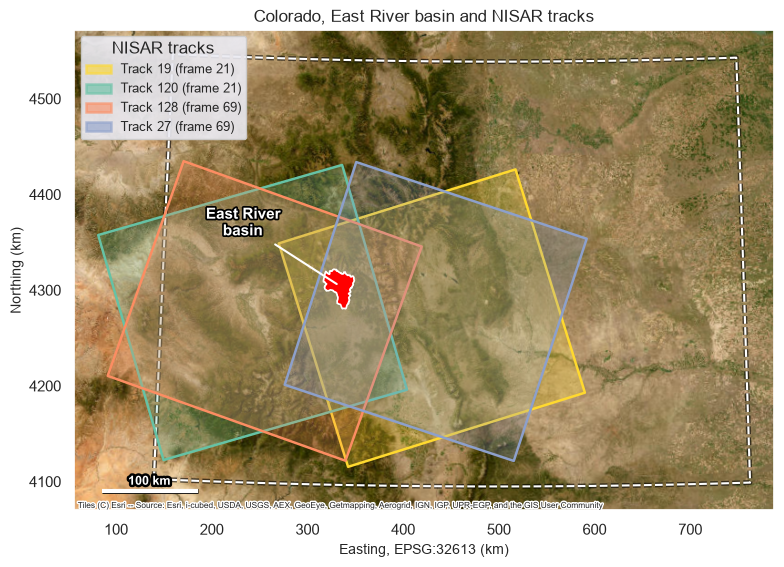

In [11]:
colorado = gpd.GeoSeries([shapely.segmentize(box(*CO_BOUNDS_LONLAT), 0.05)], crs='EPSG:4326').to_crs(crs)


def plot_colorado(basemap=BASEMAPS[BASEMAP_DEFAULT], savename=None):
    fig, ax = plt.subplots(figsize=CO_FIGSIZE)

    # extent covers Colorado and all track footprints
    xmin, ymin, xmax, ymax = shapely.union_all([colorado.union_all(), footprints.union_all()]).bounds
    xlim = (xmin - CO_PAD_M, xmax + CO_PAD_M)
    ylim = (ymin - CO_PAD_M, ymax + CO_PAD_M)
    ax.set_aspect('equal')

    # basemap tiles are warped to our UTM zone; fetch a bigger area than we show, then crop to the map extent
    m = BASEMAP_TILE_MARGIN_M
    ax.set_xlim(xlim[0] - m, xlim[1] + m)
    ax.set_ylim(ylim[0] - m, ylim[1] + m)
    ctx.add_basemap(ax, crs=crs, source=basemap, zoom=BASEMAP_ZOOM, attribution_size=BASEMAP_ATTRIBUTION_SIZE, reset_extent=False)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

    colorado.plot(ax=ax, **CO_STYLE)

    handles = []
    for row in footprints.itertuples():
        color = TRACK_COLORS[row.track]
        gpd.GeoSeries([row.geometry]).plot(ax=ax, facecolor=color, alpha=TRACK_FILL_ALPHA, edgecolor='none')
        gpd.GeoSeries([row.geometry]).plot(ax=ax, facecolor='none', edgecolor=color, linewidth=TRACK_EDGE_WIDTH)
        handles.append(Patch(facecolor=color, alpha=0.6, edgecolor=color, linewidth=TRACK_EDGE_WIDTH,
                             label=TRACK_LEGEND_LABEL.format(track=row.track, frame=row.frame)))

    basin.plot(ax=ax, **BASIN_CO_STYLE)
    lab = dict(BASIN_CO_LABEL)
    c = basin.union_all().centroid
    ax.annotate(lab.pop('text'), xy=(c.x, c.y), xytext=lab.pop('xytext'), textcoords='offset points',
                ha='center', va='center', arrowprops=BASIN_CO_ARROW,
                path_effects=halo_text(lab.pop('halo_color'), lab.pop('halo_width')), zorder=10, **lab)

    ax.legend(handles=handles, title=TRACK_LEGEND_TITLE, loc=TRACK_LEGEND_LOC, fontsize=9, framealpha=0.9)
    if SCALEBAR_KM:
        scalebar(ax, SCALEBAR_KM)

    ax.grid(False)
    km_ticks(ax)
    ax.set_xlabel(f'Easting, {crs.to_string()} (km)')
    ax.set_ylabel('Northing (km)')
    ax.set_title('Colorado, East River basin and NISAR tracks')
    plt.tight_layout()
    if savename and SAVE_FIGS:
        fig.savefig(out_dir + savename, dpi=FIG_DPI, bbox_inches='tight')
    plt.show()


plot_colorado(BASEMAPS['satellite'], savename='study_area_colorado_satellite.png')

To use a street basemap instead, pass `BASEMAPS['street']` (or set `BASEMAP_DEFAULT = 'street'` in the style settings and call `plot_colorado()` with no argument).

2026-10-14 21:47:10,611 - WARNING - CPLE_NotSupported in transformer options does not support option INIT_DEST


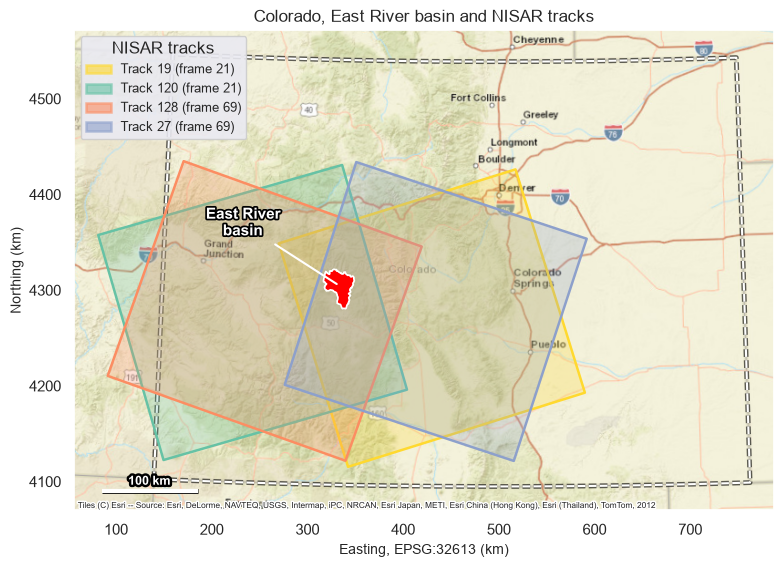

In [12]:
plot_colorado(BASEMAPS['street'], savename='study_area_colorado_street.png')

# Figure 2: DEM of the East River basin

Download the 3DEP DEM for the basin bounding box plus the buffer. 

In [13]:
bx0, by0, bx1, by1 = basin.total_bounds
extent = (bx0 - DEM_BUFFER_M, by0 - DEM_BUFFER_M, bx1 + DEM_BUFFER_M, by1 + DEM_BUFFER_M)   # (xmin, ymin, xmax, ymax) of the map
dem_aoi = box(extent[0] - DEM_DOWNLOAD_PAD_M, extent[1] - DEM_DOWNLOAD_PAD_M,
              extent[2] + DEM_DOWNLOAD_PAD_M, extent[3] + DEM_DOWNLOAD_PAD_M)

dem = py3dep.get_dem(geometry=dem_aoi, resolution=DEM_RES, crs=crs)
dem = dem.rio.write_crs(dem.rio.crs).rio.reproject(crs, resolution=DEM_RES)       # make sure we are in the map CRS
dem = dem.rio.clip_box(*extent)
logging.info(f"DEM shape {dem.shape}, CRS {dem.rio.crs}, elevation {float(dem.min()):.0f}-{float(dem.max()):.0f} m")

2026-10-14 21:47:11,325 - INFO - boto3 not available, falling back to a DummySession.


2026-10-14 21:48:50,308 - INFO - DEM shape (4536, 3636), CRS EPSG:32613, elevation 2424-4349 m


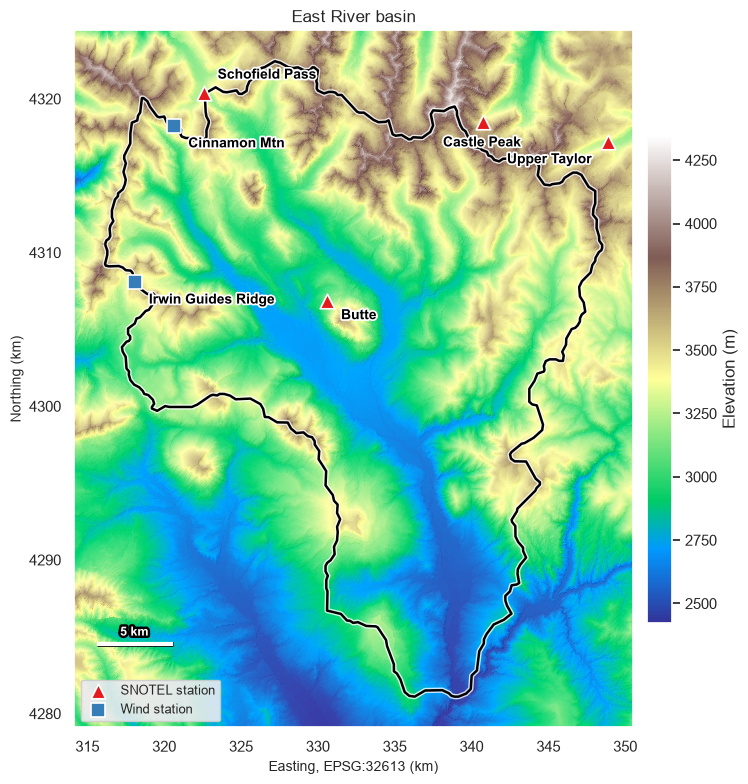

In [14]:
def hillshade_rgb(dem, cmap, vmin, vmax):
    """Color the DEM with ``cmap`` and blend in a hillshade using the HILLSHADE_* settings."""
    ls = LightSource(azdeg=HILLSHADE_AZIMUTH, altdeg=HILLSHADE_ALTITUDE)
    elev = dem.values
    dx, dy = abs(dem.rio.resolution()[0]), abs(dem.rio.resolution()[1])
    rgb = plt.get_cmap(cmap)(Normalize(vmin, vmax)(elev))[..., :3]
    return ls.shade_rgb(rgb, elev, fraction=HILLSHADE_STRENGTH, blend_mode=HILLSHADE_BLEND,
                        vert_exag=HILLSHADE_VERT_EXAG, dx=dx, dy=dy)


def plot_dem(savename=None):
    vmin = float(dem.min()) if DEM_VMIN is None else DEM_VMIN
    vmax = float(dem.max()) if DEM_VMAX is None else DEM_VMAX

    fig, ax = plt.subplots(figsize=DEM_FIGSIZE)
    left, bottom, right, top = dem.rio.bounds()
    ax.imshow(hillshade_rgb(dem, DEM_CMAP, vmin, vmax), extent=(left, right, bottom, top), origin='upper', interpolation='nearest')
    cb = fig.colorbar(ScalarMappable(Normalize(vmin, vmax), cmap=DEM_CMAP), ax=ax, shrink=0.7, pad=0.02)
    cb.set_label('Elevation (m)')

    # basin outline
    if BASIN_DEM_HALO:
        basin.boundary.plot(ax=ax, **BASIN_DEM_HALO)
    basin.boundary.plot(ax=ax, **{k: v for k, v in BASIN_DEM_STYLE.items() if k != 'facecolor'})

    # stations
    stations = gpd.GeoDataFrame(STATIONS, geometry=gpd.points_from_xy([s['lon'] for s in STATIONS], [s['lat'] for s in STATIONS]), crs='EPSG:4326').to_crs(crs)
    for kind, style in MARKER_STYLE.items():
        sub = stations[stations['kind'] == kind]
        ax.scatter(sub.geometry.x, sub.geometry.y, zorder=5, **style)
    label_style = dict(LABEL_STYLE)
    halo = halo_text(label_style.pop('halo_color'), label_style.pop('halo_width'))
    for s in stations.itertuples():
        ax.annotate(s.name, xy=(s.geometry.x, s.geometry.y), xytext=(s.dx, s.dy), textcoords='offset points',
                    ha=s.ha, va=s.va, path_effects=halo, zorder=6, **label_style)

    ax.set_xlim(extent[0], extent[2])
    ax.set_ylim(extent[1], extent[3])
    ax.set_aspect('equal')
    ax.grid(False)
    if DEM_AXIS_KM:
        km_ticks(ax)
        ax.set_xlabel(f'Easting, {crs.to_string()} (km)')
        ax.set_ylabel('Northing (km)')
    else:
        ax.set_xlabel(f'Easting, {crs.to_string()} (m)')
        ax.set_ylabel('Northing (m)')
    ax.set_title(DEM_TITLE)
    ax.legend(**LEGEND_STYLE)
    if DEM_SCALEBAR_KM:
        scalebar(ax, DEM_SCALEBAR_KM, loc=(0.04, 0.12), color='white', halo='black')
    plt.tight_layout()
    if savename and SAVE_FIGS:
        fig.savefig(out_dir + savename, dpi=FIG_DPI, bbox_inches='tight')
    plt.show()


plot_dem(savename='study_area_dem.png')